# Week 06 — YCB-V Error Analysis II
**Group 1 | Main Quest: Structuring Machine Learning Projects**  
**Side Quest: Error Analysis II — Evidence → Targeted Experiments → Recommendation**

This notebook is the direct continuation of Week 05. It converts the **measured Week 05 failure patterns** into a small set of **one-variable-at-a-time experiments** instead of making random model changes.

The Week 05 evidence carried forward exactly is:
- selected Week 04 model: `E1_regularization` (Adam, lr=1e-3, dropout=0.30, weight_decay=1e-4, no augmentation),
- 877 / 375 / 450 samples over 8 / 2 / 2 scenes,
- held-out-scene test accuracy: **188 / 450 = 41.78%**,
- validation accuracy: **98.93%**,
- largest failures: `tuna → tomato = 69`, `sugar → bleach = 46`, `tomato → bleach = 45`,
- class recalls: tomato 49.33%, sugar 38.67%, master 90.67%, tuna 8.00%, bleach 14.67%.

**Important evaluation rule:** the original Week 04 test scenes remain untouched during experiment selection. Targeted experiments are compared on repeated **scene-held-out development splits**. Only the selected configuration is evaluated once on the original held-out test scenes.

## Part A — Re-establish the exact Week 05 evidence
The purpose of this section is not to retrain anything. It makes the Week 06 decision trace auditable: each experiment below must map to a specific observed failure.

In [1]:
from pathlib import Path
import os, json, random, math, time, zipfile, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, accuracy_score, f1_score

SEED = 42
CLASSES = [
    "tomato_soup_can", "sugar_box", "master_chef_can",
    "tuna_fish_can", "bleach_cleanser",
]
SELECTED_OBJ_IDS = [4, 3, 1, 6, 12]

# Exact Week 04 E1 matrix verified in Week 05.
W4_E1_CM = np.array([
    [74,  0,  0, 31, 45],
    [ 0, 29,  0,  0, 46],
    [ 7,  0, 68,  0,  0],
    [69,  0,  0,  6,  0],
    [32, 12,  0, 20, 11],
], dtype=int)
W4_VAL_ACC = 0.9893333333333333
W4_TEST_ACC = 188/450
W4_TRAIN_ACC = 1.0

assert W4_E1_CM.sum() == 450 and np.trace(W4_E1_CM) == 188

true = np.repeat(np.arange(5), W4_E1_CM.sum(axis=1))
pred = np.concatenate([
    np.repeat(np.arange(5), W4_E1_CM[r]) for r in range(5)
])
precision, recall, f1, support = precision_recall_fscore_support(
    true, pred, labels=np.arange(5), zero_division=0
)
per_class = pd.DataFrame({
    'class': CLASSES, 'support': support,
    'precision': precision, 'recall': recall, 'f1': f1,
    'errors': support - np.diag(W4_E1_CM),
})
print(f'Week 04 / Week 05 verified held-out accuracy: {W4_TEST_ACC:.2%} (188/450)')
print(f'Validation–test gap: {(W4_VAL_ACC-W4_TEST_ACC)*100:.2f} percentage points')
display(per_class.round(4))

Week 04 / Week 05 verified held-out accuracy: 41.78% (188/450)
Validation–test gap: 57.16 percentage points


,class,support,precision,recall,f1,errors
0,tomato_soup_can,150,0.4066,0.4933,0.4458,76
1,sugar_box,75,0.7073,0.3867,0.5000,46
2,master_chef_can,75,1.0000,0.9067,0.9510,7
3,tuna_fish_can,75,0.1053,0.0800,0.0909,69
4,bleach_cleanser,75,0.1078,0.1467,0.1243,64


,true_class,pred_class,count,pct_of_true_class,pct_of_all_errors
0,tuna_fish_can,tomato_soup_can,69,92.00%,26.34%
1,sugar_box,bleach_cleanser,46,61.33%,17.56%
2,tomato_soup_can,bleach_cleanser,45,30.00%,17.18%
3,bleach_cleanser,tomato_soup_can,32,42.67%,12.21%
4,tomato_soup_can,tuna_fish_can,31,20.67%,11.83%
5,bleach_cleanser,tuna_fish_can,20,26.67%,7.63%
6,bleach_cleanser,sugar_box,12,16.00%,4.58%
7,master_chef_can,tomato_soup_can,7,9.33%,2.67%


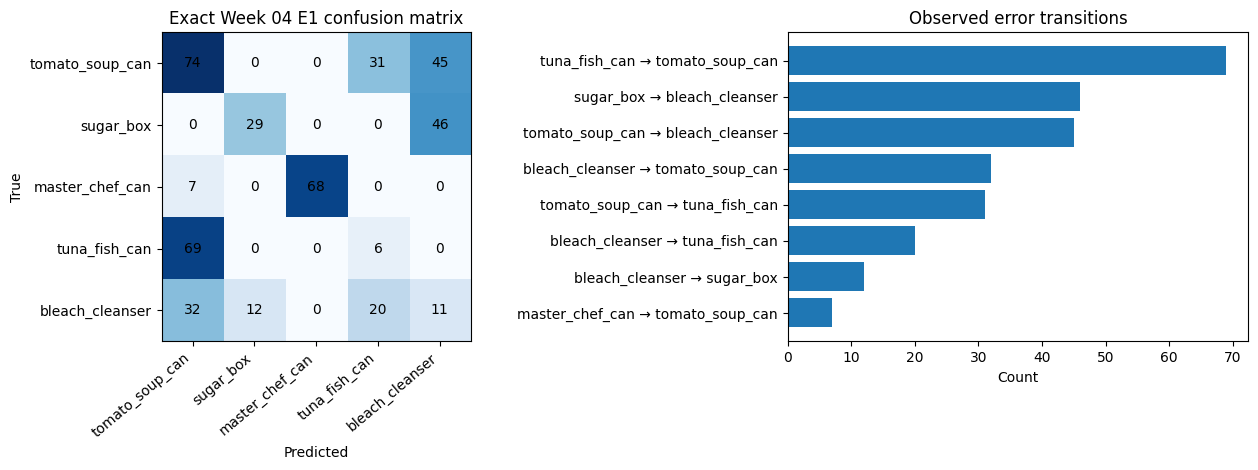

In [2]:
# Exact directed transitions from the Week 05 matrix.
transitions=[]
for i,t in enumerate(CLASSES):
    for j,p in enumerate(CLASSES):
        if i != j and W4_E1_CM[i,j] > 0:
            transitions.append({
                'true_class': t, 'pred_class': p,
                'count': int(W4_E1_CM[i,j]),
                'pct_of_true_class': W4_E1_CM[i,j] / W4_E1_CM[i].sum(),
                'pct_of_all_errors': W4_E1_CM[i,j] / (450-188),
            })
transitions = pd.DataFrame(transitions).sort_values('count', ascending=False).reset_index(drop=True)
display(transitions.style.format({'pct_of_true_class':'{:.2%}','pct_of_all_errors':'{:.2%}'}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
im=axes[0].imshow(W4_E1_CM, cmap='Blues')
axes[0].set_xticks(range(5), CLASSES, rotation=40, ha='right')
axes[0].set_yticks(range(5), CLASSES)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
axes[0].set_title('Exact Week 04 E1 confusion matrix')
for i in range(5):
    for j in range(5): axes[0].text(j,i,str(W4_E1_CM[i,j]),ha='center',va='center')

axes[1].barh(
    [f"{r.true_class} → {r.pred_class}" for _,r in transitions.iterrows()][::-1],
    transitions['count'].tolist()[::-1]
)
axes[1].set_title('Observed error transitions')
axes[1].set_xlabel('Count')
plt.tight_layout(); plt.show()

## Part B — Decision process: evidence → hypothesis → one targeted change
Week 06 deliberately avoids a broad hyperparameter sweep. Each candidate changes **one causal lever** while keeping optimizer, learning rate, dropout, weight decay, dataset filters, class set, and test set policy fixed.

The three chosen experiments answer different questions:
1. **Context ablation:** is the 8% padded crop causing the classifier to rely on scene/background cues that fail in new scenes?
2. **Geometry ablation:** is forcing every rectangular crop directly into 64×64 distorting object proportions enough to hurt class separation?
3. **Spatial inductive bias:** is the flattened MLP overly sensitive to exact pixel location/background, so a small CNN generalizes better across scenes?

The first two are preprocessing-only tests. The third is the only model-family change, and it is included because the original architecture flattens all pixels and therefore has no translation-aware spatial structure.

In [3]:
experiment_plan = pd.DataFrame([
    {
        'id':'B0_control',
        'observed_evidence':'Week 04 E1 baseline; 57.15-point val→test gap',
        'hypothesis':'Reference condition',
        'single_change':'None',
        'padding':0.08, 'resize':'direct 64×64', 'model':'MLP',
    },
    {
        'id':'X1_no_context_padding',
        'observed_evidence':'Wrong examples include nearby objects/context; tuna→tomato=69 and bleach errors spread across 3 labels',
        'hypothesis':'Background/context inside the padded crop is spuriously predictive',
        'single_change':'Crop padding 8% → 0%',
        'padding':0.00, 'resize':'direct 64×64', 'model':'MLP',
    },
    {
        'id':'X2_preserve_aspect_ratio',
        'observed_evidence':'Cross-scene/viewpoint mismatch is plausible; classes have distinct package geometry',
        'hypothesis':'Direct square resize distorts object shape and aspect cues',
        'single_change':'Direct resize → aspect-preserving letterbox',
        'padding':0.08, 'resize':'letterbox 64×64', 'model':'MLP',
    },
    {
        'id':'X3_compact_cnn',
        'observed_evidence':'Near-perfect train/val fit but weak new-scene test; flattened RGB is location-sensitive',
        'hypothesis':'A small CNN should learn more local/spatial features and less absolute-pixel memorization',
        'single_change':'MLP → compact CNN',
        'padding':0.08, 'resize':'direct 64×64', 'model':'CNN',
    },
])
display(experiment_plan)

,id,observed_evidence,hypothesis,single_change,padding,resize,model
0,B0_control,Week 04 E1 baseline; 57.15-point val→test gap,Reference condition,None,0.08,direct 64×64,MLP
1,X1_no_context_padding,Wrong examples include nearby objects/context;...,Background/context inside the padded crop is s...,Crop padding 8% → 0%,0.00,direct 64×64,MLP
2,X2_preserve_aspect_ratio,Cross-scene/viewpoint mismatch is plausible; c...,Direct square resize distorts object shape and...,Direct resize → aspect-preserving letterbox,0.08,letterbox 64×64,MLP
3,X3_compact_cnn,Near-perfect train/val fit but weak new-scene ...,A small CNN should learn more local/spatial fe...,MLP → compact CNN,0.08,direct 64×64,CNN


### Selection rule
To prevent another “great validation / poor unseen scene” choice:
- build **3 deterministic repeated scene-held-out development splits** from the original Week 04 train+validation scenes;
- primary metric = **mean macro-F1** across those splits;
- secondary metric = mean accuracy;
- also track mean recall for the four problematic classes: tomato, sugar, tuna, bleach;
- the original 2 test scenes are never used to choose an experiment;
- after choosing the best single-change experiment, retrain it on the **original Week 04 train split**, early-stop on the **original Week 04 validation split**, and evaluate the original test **once**.

This keeps diagnosis and model selection separate from the final held-out evidence.

## Part C — Reproduce the exact Week 04 data pipeline
Run this notebook in Google Colab. The first full run downloads the same ~660 MB BOP'19 YCB-V test subset used in Week 03/04. For packaging/review only, `WEEK06_PLAN_ONLY=1` skips network/data-dependent cells without inventing results.

In [4]:
PLAN_ONLY = os.getenv('WEEK06_PLAN_ONLY', '0') == '1'
DATASETS_DIR = Path('datasets')
DOWNLOAD_DIR = DATASETS_DIR / 'downloads'
DATASET_ROOT = DATASETS_DIR / 'ycbv'
OUTPUT_DIR = Path('outputs/week06')
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
for p in [DOWNLOAD_DIR, DATASET_ROOT, OUTPUT_DIR, CHECKPOINT_DIR]: p.mkdir(parents=True, exist_ok=True)

N_CLASSES=5; IMAGE_SIZE=64; BATCH_SIZE=64
MAX_EPOCHS=15; EARLY_STOPPING_PATIENCE=4
MIN_VISIBILITY=0.35; MIN_BOX_SIDE=24
MAX_TRAIN_PER_CLASS=600; MAX_VAL_PER_CLASS=150; MAX_TEST_PER_CLASS=150

DATASET_READY = (DATASET_ROOT/'test').exists() and any((DATASET_ROOT/'test').iterdir()) if (DATASET_ROOT/'test').exists() else False
if PLAN_ONLY:
    print('PLAN_ONLY=1 → data download/training is intentionally skipped in this packaged copy.')
elif not DATASET_READY:
    from huggingface_hub import hf_hub_download
    REPO_ID='bop-benchmark/ycbv'
    def download_hf(filename):
        try: return Path(hf_hub_download(repo_id=REPO_ID, filename=filename, repo_type='dataset'))
        except Exception: return Path(hf_hub_download(repo_id=REPO_ID, filename=filename))
    base_zip=download_hf('ycbv_base.zip')
    test_zip=download_hf('ycbv_test_bop19.zip')
    with zipfile.ZipFile(base_zip,'r') as zf: zf.extractall(DATASET_ROOT)
    with zipfile.ZipFile(test_zip,'r') as zf: zf.extractall(DATASET_ROOT)
    DATASET_READY=True
print('Dataset ready:', DATASET_READY)

ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

Dataset ready: True


In [5]:
if DATASET_READY:
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms
    from PIL import Image, ImageOps
    from sklearn.metrics import classification_report

    def seed_everything(seed=SEED):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    seed_everything()
    DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Device:', DEVICE)

    YCBV_OBJECTS={
        1:'master_chef_can',2:'cracker_box',3:'sugar_box',4:'tomato_soup_can',5:'mustard_bottle',
        6:'tuna_fish_can',7:'pudding_box',8:'gelatin_box',9:'potted_meat_can',10:'banana',
        11:'pitcher_base',12:'bleach_cleanser',13:'bowl',14:'mug',15:'power_drill',16:'wood_block',
        17:'scissors',18:'large_marker',19:'large_clamp',20:'extra_large_clamp',21:'foam_brick'
    }
    def load_json(path):
        with open(path,'r',encoding='utf-8') as f: return json.load(f)
    def build_instance_table(dataset_root):
        rows=[]; test_root=dataset_root/'test'
        for scene_dir in sorted([p for p in test_root.iterdir() if p.is_dir()]):
            scene_id=int(scene_dir.name); gt=load_json(scene_dir/'scene_gt.json'); info=load_json(scene_dir/'scene_gt_info.json')
            for im_key, objects in gt.items():
                infos=info[im_key]; im_id=int(im_key)
                rgb=scene_dir/'rgb'/f'{im_id:06d}.png'
                if not rgb.exists():
                    jpg=scene_dir/'rgb'/f'{im_id:06d}.jpg'; rgb=jpg if jpg.exists() else rgb
                for instance_idx,(obj,obj_info) in enumerate(zip(objects,infos)):
                    obj_id=int(obj['obj_id']); bbox=obj_info.get('bbox_obj') or obj_info.get('bbox_visib')
                    vis=float(obj_info.get('visib_fract',1.0))
                    if bbox is None: continue
                    x,y,w,h=[int(round(v)) for v in bbox]
                    if w<MIN_BOX_SIDE or h<MIN_BOX_SIDE or vis<MIN_VISIBILITY or not rgb.exists(): continue
                    rows.append(dict(scene_id=scene_id,im_id=im_id,instance_idx=instance_idx,obj_id=obj_id,
                                     class_name=YCBV_OBJECTS.get(obj_id,f'obj_{obj_id:02d}'),x=x,y=y,w=w,h=h,
                                     visib_fract=vis,rgb_path=str(rgb)))
        return pd.DataFrame(rows)

    instances_df=build_instance_table(DATASET_ROOT)
    class_stats=(instances_df.groupby(['obj_id','class_name']).agg(samples=('obj_id','size'),scenes=('scene_id','nunique'),
                  mean_visibility=('visib_fract','mean')).reset_index().sort_values(['scenes','samples'],ascending=False))
    selected_stats=class_stats[class_stats.scenes>=3].head(N_CLASSES).copy()
    assert selected_stats.obj_id.tolist()==SELECTED_OBJ_IDS, selected_stats
    selected_df=instances_df[instances_df.obj_id.isin(SELECTED_OBJ_IDS)].copy()

    def all_classes_present(df,obj_ids): return set(obj_ids).issubset(set(df.obj_id.unique().tolist()))
    def find_scene_split(df,obj_ids,train_frac=.70,val_frac=.15,attempts=5000):
        scenes=np.array(sorted(df.scene_id.unique())); n=len(scenes)
        n_test=max(1,int(round(n*(1-train_frac-val_frac)))); n_val=max(1,int(round(n*val_frac))); n_train=n-n_val-n_test
        for attempt in range(attempts):
            rng=np.random.default_rng(SEED+attempt); sh=rng.permutation(scenes)
            ts=set(sh[:n_train]); vs=set(sh[n_train:n_train+n_val]); tes=set(sh[n_train+n_val:])
            parts=[df[df.scene_id.isin(s)] for s in (ts,vs,tes)]
            if all(all_classes_present(p,obj_ids) for p in parts): return [p.copy() for p in parts]
        raise RuntimeError('Could not reproduce original scene-level split')
    def cap_per_class(df,max_per_class,seed):
        parts=[]
        for obj_id,g in df.groupby('obj_id'): parts.append(g.sample(n=min(len(g),max_per_class),random_state=seed))
        return pd.concat(parts,ignore_index=True).sample(frac=1,random_state=seed).reset_index(drop=True)

    train_df,val_df,test_df=find_scene_split(selected_df,SELECTED_OBJ_IDS)
    train_df=cap_per_class(train_df,MAX_TRAIN_PER_CLASS,SEED)
    val_df=cap_per_class(val_df,MAX_VAL_PER_CLASS,SEED)
    test_df=cap_per_class(test_df,MAX_TEST_PER_CLASS,SEED)
    assert (len(train_df),len(val_df),len(test_df))==(877,375,450)
    assert set(train_df.scene_id).isdisjoint(val_df.scene_id) and set(train_df.scene_id).isdisjoint(test_df.scene_id)
    assert set(val_df.scene_id).isdisjoint(test_df.scene_id)
    print('Reproduced Week 04 split:', len(train_df),len(val_df),len(test_df), 'samples')
    print('Scenes:', train_df.scene_id.nunique(), val_df.scene_id.nunique(), test_df.scene_id.nunique())
else:
    print('Data-dependent pipeline skipped. Run normally in Colab to reproduce the original split.')

Device: cpu
Reproduced Week 04 split: 877 375 450 samples
Scenes: 8 2 2


## Part D — Build repeated cross-scene development splits
The development pool is Week 04 **train + validation only**. The original test remains excluded. Each repeated split holds out whole scenes and is accepted only when all five classes are present on both sides.

In [6]:
def make_repeated_scene_splits(dev_df, n_splits=3, val_scene_fraction=0.25, seed=SEED, max_attempts=5000):
    scenes=np.array(sorted(dev_df.scene_id.unique())); n_hold=max(1,round(len(scenes)*val_scene_fraction))
    splits=[]; seen=set()
    for attempt in range(max_attempts):
        rng=np.random.default_rng(seed+1000+attempt); held=tuple(sorted(rng.choice(scenes,size=n_hold,replace=False).tolist()))
        if held in seen: continue
        tr=dev_df[~dev_df.scene_id.isin(held)].copy(); va=dev_df[dev_df.scene_id.isin(held)].copy()
        if all_classes_present(tr,SELECTED_OBJ_IDS) and all_classes_present(va,SELECTED_OBJ_IDS):
            seen.add(held); splits.append((tr,va,held))
            if len(splits)==n_splits: return splits
    raise RuntimeError('Could not create enough all-class scene-held-out development splits')

if DATASET_READY:
    dev_pool=pd.concat([train_df,val_df],ignore_index=True)
    DEV_SPLITS=make_repeated_scene_splits(dev_pool,n_splits=3)
    for i,(tr,va,held) in enumerate(DEV_SPLITS,1):
        print(f'Split {i}: train={len(tr)} across {tr.scene_id.nunique()} scenes | dev={len(va)} across {va.scene_id.nunique()} scenes | held scenes={held}')
else:
    DEV_SPLITS=[]; print('Skipped until dataset is available.')

Split 1: train=877 across 8 scenes | dev=375 across 2 scenes | held scenes=(52, 55)
Split 2: train=802 across 8 scenes | dev=450 across 2 scenes | held scenes=(49, 55)
Split 3: train=802 across 8 scenes | dev=450 across 2 scenes | held scenes=(48, 55)


## Part E — Targeted preprocessing and models
All training hyperparameters are fixed across B0/X1/X2/X3. The experiment ID controls only the factor listed in Part B.

In [7]:
if DATASET_READY:
    eval_transform=transforms.Compose([
        transforms.ToTensor(), transforms.Normalize(mean=[.5]*3,std=[.5]*3)
    ])
    label_map={obj_id:i for i,obj_id in enumerate(SELECTED_OBJ_IDS)}

    def object_crop(row,padding=.08):
        with Image.open(row['rgb_path']) as raw:
            im=raw.convert('RGB'); W,H=im.size
            x,y,w,h=(int(row[k]) for k in ('x','y','w','h'))
            px,py=int(w*padding),int(h*padding)
            return im.crop((max(0,x-px),max(0,y-py),min(W,x+w+px),min(H,y+h+py)))

    def resize_direct(im,size=IMAGE_SIZE):
        return im.resize((size,size), Image.Resampling.BILINEAR)
    def resize_letterbox(im,size=IMAGE_SIZE):
        contained=ImageOps.contain(im,(size,size),method=Image.Resampling.BILINEAR)
        canvas=Image.new('RGB',(size,size),(127,127,127))
        x=(size-contained.width)//2; y=(size-contained.height)//2
        canvas.paste(contained,(x,y)); return canvas

    class CropDataset(Dataset):
        def __init__(self, frame, padding=.08, letterbox=False):
            self.df=frame.reset_index(drop=True); self.padding=padding; self.letterbox=letterbox
        def __len__(self): return len(self.df)
        def __getitem__(self,idx):
            row=self.df.iloc[idx]; im=object_crop(row,self.padding)
            im=resize_letterbox(im) if self.letterbox else resize_direct(im)
            return eval_transform(im), label_map[int(row.obj_id)]

    class RegularizedMLP(nn.Module):
        def __init__(self,dropout=.30):
            super().__init__(); d=3*IMAGE_SIZE*IMAGE_SIZE
            self.net=nn.Sequential(nn.Flatten(),nn.Linear(d,256),nn.ReLU(),nn.Dropout(dropout),
                                   nn.Linear(256,128),nn.ReLU(),nn.Dropout(dropout),nn.Linear(128,N_CLASSES))
        def forward(self,x): return self.net(x)

    class CompactCNN(nn.Module):
        def __init__(self,dropout=.30):
            super().__init__()
            self.features=nn.Sequential(
                nn.Conv2d(3,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                nn.Conv2d(64,96,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((4,4)),
            )
            self.head=nn.Sequential(nn.Flatten(),nn.Linear(96*4*4,128),nn.ReLU(),nn.Dropout(dropout),nn.Linear(128,N_CLASSES))
        def forward(self,x): return self.head(self.features(x))

    EXPERIMENTS=[
        dict(id='B0_control',padding=.08,letterbox=False,model='mlp'),
        dict(id='X1_no_context_padding',padding=0.0,letterbox=False,model='mlp'),
        dict(id='X2_preserve_aspect_ratio',padding=.08,letterbox=True,model='mlp'),
        dict(id='X3_compact_cnn',padding=.08,letterbox=False,model='cnn'),
    ]
    display(pd.DataFrame(EXPERIMENTS))
else:
    EXPERIMENTS=[]; print('Model definitions skipped until dataset is available.')

,id,padding,letterbox,model
0,B0_control,0.08,False,mlp
1,X1_no_context_padding,0.00,False,mlp
2,X2_preserve_aspect_ratio,0.08,True,mlp
3,X3_compact_cnn,0.08,False,cnn


## Part F — Training/evaluation utilities
Same optimizer/lr/weight decay/dropout and early-stopping rule are used for every experiment. This is the orthogonalization step: the factor under test is isolated.

In [8]:
if DATASET_READY:
    def make_model(cfg):
        return (RegularizedMLP(.30) if cfg['model']=='mlp' else CompactCNN(.30)).to(DEVICE)

    def loaders_for(train_frame, val_frame, cfg, seed):
        tr_ds=CropDataset(train_frame,cfg['padding'],cfg['letterbox'])
        va_ds=CropDataset(val_frame,cfg['padding'],cfg['letterbox'])
        g=torch.Generator().manual_seed(seed)
        tr=DataLoader(tr_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,generator=g)
        va=DataLoader(va_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
        return tr,va

    @torch.no_grad()
    def predict(model,loader):
        model.eval(); ys=[]; ps=[]
        for x,y in loader:
            logits=model(x.to(DEVICE)); pred=logits.argmax(1).cpu().numpy()
            ys.extend(y.numpy().tolist()); ps.extend(pred.tolist())
        return np.array(ys),np.array(ps)

    def train_one(train_frame,val_frame,cfg,run_seed,save_path=None):
        seed_everything(run_seed); model=make_model(cfg)
        tr,va=loaders_for(train_frame,val_frame,cfg,run_seed)
        opt=torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-4)
        loss_fn=nn.CrossEntropyLoss(); best_loss=float('inf'); best_state=None; patience=0; best_epoch=0
        history=[]
        for epoch in range(1,MAX_EPOCHS+1):
            model.train(); total=correct=n=0
            for x,y in tr:
                x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(); logits=model(x); loss=loss_fn(logits,y); loss.backward(); opt.step()
                total += loss.item()*len(y); correct += (logits.argmax(1)==y).sum().item(); n += len(y)
            model.eval(); vloss=vc=vn=0
            with torch.no_grad():
                for x,y in va:
                    x,y=x.to(DEVICE),y.to(DEVICE); logits=model(x); loss=loss_fn(logits,y)
                    vloss += loss.item()*len(y); vc += (logits.argmax(1)==y).sum().item(); vn += len(y)
            tr_loss=total/n; tr_acc=correct/n; val_loss=vloss/vn; val_acc=vc/vn
            history.append((epoch,tr_loss,tr_acc,val_loss,val_acc))
            if val_loss < best_loss-1e-6:
                best_loss=val_loss; best_state=copy.deepcopy(model.state_dict()); best_epoch=epoch; patience=0
            else:
                patience += 1
                if patience>=EARLY_STOPPING_PATIENCE: break
        model.load_state_dict(best_state)
        if save_path is not None: torch.save(best_state,save_path)
        y,p=predict(model,va)
        rec=precision_recall_fscore_support(y,p,labels=np.arange(5),zero_division=0)[1]
        return dict(model=model,best_epoch=best_epoch,val_loss=best_loss,accuracy=accuracy_score(y,p),
                    macro_f1=f1_score(y,p,average='macro',labels=np.arange(5),zero_division=0),recalls=rec,history=history)
else:
    print('Training utilities skipped.')

## Part G — Run the targeted experiments on repeated unseen-scene development splits
This is the actual Week 06 experiment block. It runs B0/X1/X2/X3 on the **same three scene-held-out splits** and saves fold-level evidence.

In [9]:
if DATASET_READY:
    rows=[]
    for cfg in EXPERIMENTS:
        print('\n'+'='*90+'\n',cfg['id'])
        for fold,(tr,va,held) in enumerate(DEV_SPLITS,1):
            r=train_one(tr,va,cfg,SEED+fold)
            row=dict(experiment=cfg['id'],fold=fold,held_scenes=';'.join(map(str,held)),best_epoch=r['best_epoch'],
                     val_loss=r['val_loss'],accuracy=r['accuracy'],macro_f1=r['macro_f1'])
            for i,name in enumerate(CLASSES): row[f'recall_{name}']=r['recalls'][i]
            rows.append(row)
            print(f"fold {fold}: macro-F1={r['macro_f1']:.4f} acc={r['accuracy']:.4f} epoch={r['best_epoch']}")
    fold_results=pd.DataFrame(rows)
    fold_results.to_csv(OUTPUT_DIR/'week06_fold_results.csv',index=False)
    display(fold_results.round(4))
else:
    fold_results=pd.DataFrame(); print('Targeted runs skipped in PLAN_ONLY package. Run all cells normally in Colab.')


 B0_control
fold 1: macro-F1=0.9867 acc=0.9867 epoch=4
fold 2: macro-F1=0.8581 acc=0.8289 epoch=1
fold 3: macro-F1=0.8151 acc=0.7911 epoch=1

 X1_no_context_padding
fold 1: macro-F1=0.9787 acc=0.9787 epoch=1
fold 2: macro-F1=0.9960 acc=0.9956 epoch=7
fold 3: macro-F1=0.8256 acc=0.8044 epoch=1

 X2_preserve_aspect_ratio
fold 1: macro-F1=0.9947 acc=0.9947 epoch=7
fold 2: macro-F1=1.0000 acc=1.0000 epoch=5
fold 3: macro-F1=0.9604 acc=0.9533 epoch=5

 X3_compact_cnn
fold 1: macro-F1=0.7223 acc=0.7813 epoch=6
fold 2: macro-F1=0.8569 acc=0.8222 epoch=6
fold 3: macro-F1=0.5707 acc=0.6311 epoch=1


,experiment,fold,held_scenes,best_epoch,val_loss,accuracy,macro_f1,recall_tomato_soup_can,recall_sugar_box,recall_master_chef_can,recall_tuna_fish_can,recall_bleach_cleanser
0,B0_control,1,52;55,4,0.0432,0.9867,0.9867,0.9733,1.0000,0.9600,1.0000,1.0000
1,B0_control,2,49;55,1,0.5098,0.8289,0.8581,0.9733,0.5267,0.9467,1.0000,1.0000
2,B0_control,3,48;55,1,1.4358,0.7911,0.8151,1.0000,0.8267,0.5067,0.9333,0.9733
3,X1_no_context_padding,1,52;55,1,0.0459,0.9787,0.9787,1.0000,1.0000,0.9467,0.9467,1.0000
4,X1_no_context_padding,2,49;55,7,0.0123,0.9956,0.9960,1.0000,0.9867,1.0000,1.0000,1.0000
5,X1_no_context_padding,3,48;55,1,1.1027,0.8044,0.8256,1.0000,0.9467,0.5333,0.8133,1.0000
6,X2_preserve_aspect_ratio,1,52;55,7,0.0102,0.9947,0.9947,1.0000,1.0000,1.0000,0.9733,1.0000
7,X2_preserve_aspect_ratio,2,49;55,5,0.0001,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
8,X2_preserve_aspect_ratio,3,48;55,5,0.1091,0.9533,0.9604,1.0000,1.0000,0.8600,1.0000,1.0000
9,X3_compact_cnn,1,52;55,6,0.5721,0.7813,0.7223,1.0000,0.0000,0.9867,1.0000,0.9200


,experiment,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,recall_tomato_soup_can_mean,recall_sugar_box_mean,recall_master_chef_can_mean,recall_tuna_fish_can_mean,recall_bleach_cleanser_mean
2,X2_preserve_aspect_ratio,0.9827,0.0255,0.9850,0.0215,1.0000,1.0000,0.9533,0.9911,1.0000
1,X1_no_context_padding,0.9262,0.1058,0.9334,0.0938,1.0000,0.9778,0.8267,0.9200,1.0000
0,B0_control,0.8689,0.1037,0.8866,0.0893,0.9822,0.7844,0.8044,0.9778,0.9911
3,X3_compact_cnn,0.7449,0.1006,0.7166,0.1432,0.9289,0.1667,0.8244,1.0000,0.9556


Selected targeted experiment: X2_preserve_aspect_ratio


,experiment,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,recall_tomato_soup_can_mean,recall_sugar_box_mean,recall_master_chef_can_mean,recall_tuna_fish_can_mean,recall_bleach_cleanser_mean,macro_f1_delta_vs_control,accuracy_delta_vs_control,worst_target_recall_delta_vs_control
2,X2_preserve_aspect_ratio,0.9827,0.0255,0.9850,0.0215,1.0000,1.0000,0.9533,0.9911,1.0000,0.0984,0.1138,0.0089
1,X1_no_context_padding,0.9262,0.1058,0.9334,0.0938,1.0000,0.9778,0.8267,0.9200,1.0000,0.0468,0.0573,-0.0578
0,B0_control,0.8689,0.1037,0.8866,0.0893,0.9822,0.7844,0.8044,0.9778,0.9911,0.0000,0.0000,0.0000
3,X3_compact_cnn,0.7449,0.1006,0.7166,0.1432,0.9289,0.1667,0.8244,1.0000,0.9556,-0.1699,-0.1240,-0.6178


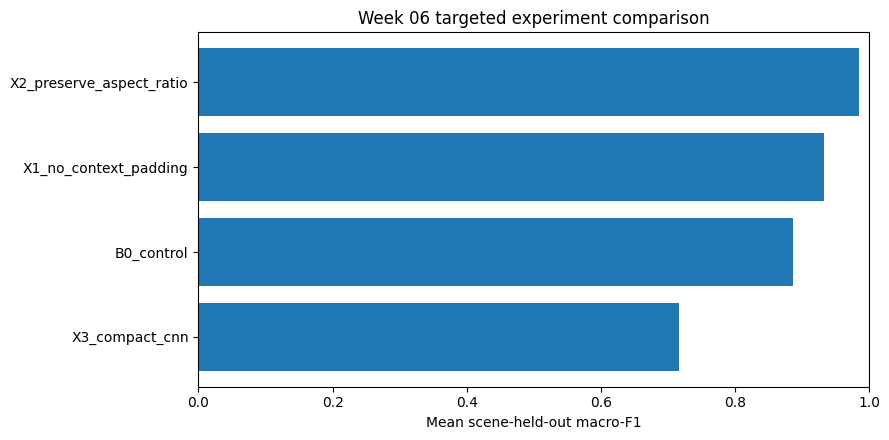

In [10]:
if len(fold_results):
    recall_cols=[f'recall_{c}' for c in CLASSES]
    agg={c:['mean','std'] for c in ['accuracy','macro_f1']}
    for c in recall_cols: agg[c]=['mean']
    summary=fold_results.groupby('experiment').agg(agg)
    summary.columns=['_'.join([a,b]).rstrip('_') for a,b in summary.columns]
    summary=summary.reset_index().sort_values('macro_f1_mean',ascending=False)
    summary.to_csv(OUTPUT_DIR/'week06_experiment_summary.csv',index=False)
    display(summary.round(4))

    control=summary[summary.experiment=='B0_control'].iloc[0]
    summary['macro_f1_delta_vs_control']=summary['macro_f1_mean']-control['macro_f1_mean']
    summary['accuracy_delta_vs_control']=summary['accuracy_mean']-control['accuracy_mean']
    target_cols=[f'recall_{c}_mean' for c in ['tomato_soup_can','sugar_box','tuna_fish_can','bleach_cleanser']]
    summary['worst_target_recall_delta_vs_control']=summary.apply(
        lambda r:min(float(r[c]-control[c]) for c in target_cols),axis=1)
    candidates=summary[summary.experiment!='B0_control'].copy()
    # Primary: macro-F1. Guardrail: do not accept a >5-point drop in any target-class mean recall.
    acceptable=candidates[candidates.worst_target_recall_delta_vs_control>=-0.05]
    pool=acceptable if len(acceptable) else candidates
    SELECTED_EXPERIMENT=pool.sort_values(['macro_f1_mean','accuracy_mean'],ascending=False).iloc[0]['experiment']
    print('Selected targeted experiment:',SELECTED_EXPERIMENT)
    display(summary.round(4))

    fig,ax=plt.subplots(figsize=(9,4.5))
    plot=summary.set_index('experiment')['macro_f1_mean'].sort_values()
    ax.barh(plot.index,plot.values); ax.set_xlim(0,1); ax.set_xlabel('Mean scene-held-out macro-F1')
    ax.set_title('Week 06 targeted experiment comparison')
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/'week06_dev_macro_f1.png',dpi=160,bbox_inches='tight'); plt.show()
else:
    summary=pd.DataFrame(); SELECTED_EXPERIMENT=None
    print('No data-dependent experiment summary yet.')

## Part H — One final held-out test for the selected experiment
Only the selected configuration is trained on the original Week 04 train split, early-stopped on the original Week 04 validation split, then evaluated once on the original test split. This preserves the original comparison protocol and prevents test-driven experiment selection.

Selected: X2_preserve_aspect_ratio
Final held-out accuracy: 0.6289 | Week04 E1: 0.4178 | delta=+0.2111
Final held-out macro-F1: 0.6468


,class,week04_recall,week06_selected_recall,delta
0,tomato_soup_can,0.4933,0.5000,0.0067
1,sugar_box,0.3867,0.3867,0.0000
2,master_chef_can,0.9067,1.0000,0.0933
3,tuna_fish_can,0.0800,1.0000,0.9200
4,bleach_cleanser,0.1467,0.3867,0.2400


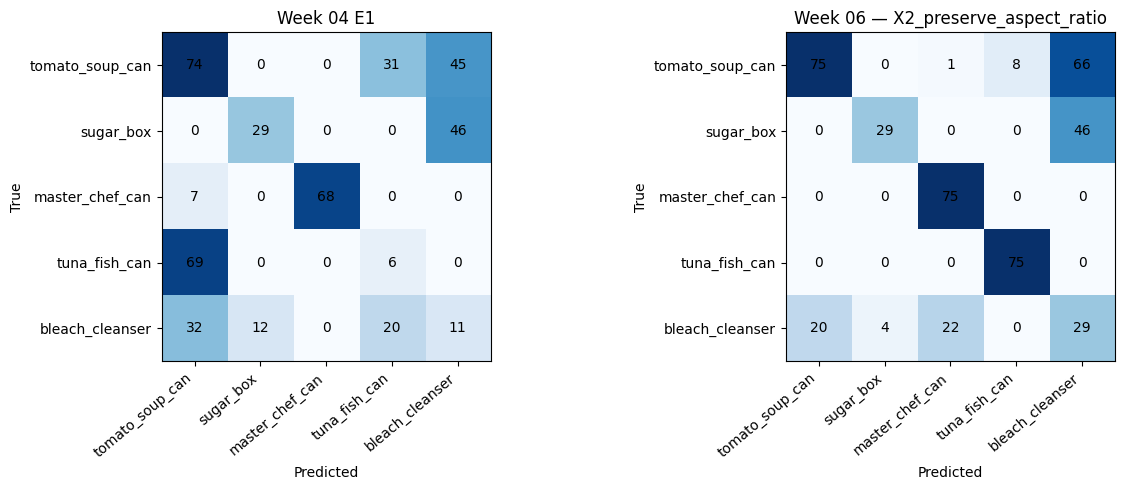

In [11]:
if DATASET_READY and SELECTED_EXPERIMENT is not None:
    selected_cfg=next(c for c in EXPERIMENTS if c['id']==SELECTED_EXPERIMENT)
    ckpt=CHECKPOINT_DIR/f'{SELECTED_EXPERIMENT}.pt'
    final_train=train_one(train_df,val_df,selected_cfg,SEED,save_path=ckpt)
    test_ds=CropDataset(test_df,selected_cfg['padding'],selected_cfg['letterbox'])
    test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    y_test,p_test=predict(final_train['model'],test_loader)
    final_acc=accuracy_score(y_test,p_test); final_macro=f1_score(y_test,p_test,average='macro',labels=np.arange(5),zero_division=0)
    final_cm=confusion_matrix(y_test,p_test,labels=np.arange(5))
    final_recalls=precision_recall_fscore_support(y_test,p_test,labels=np.arange(5),zero_division=0)[1]
    print(f'Selected: {SELECTED_EXPERIMENT}')
    print(f'Final held-out accuracy: {final_acc:.4f} | Week04 E1: {W4_TEST_ACC:.4f} | delta={final_acc-W4_TEST_ACC:+.4f}')
    print(f'Final held-out macro-F1: {final_macro:.4f}')
    display(pd.DataFrame({'class':CLASSES,'week04_recall':recall,'week06_selected_recall':final_recalls,
                          'delta':final_recalls-recall}).round(4))

    pd.DataFrame(final_cm,index=CLASSES,columns=CLASSES).to_csv(OUTPUT_DIR/'week06_final_confusion_matrix.csv')
    pd.DataFrame({'class':CLASSES,'week04_recall':recall,'week06_selected_recall':final_recalls,
                  'delta':final_recalls-recall}).to_csv(OUTPUT_DIR/'week06_recall_delta.csv',index=False)
    final_record={'selected_experiment':SELECTED_EXPERIMENT,'final_test_accuracy':float(final_acc),
                  'week04_test_accuracy':float(W4_TEST_ACC),'accuracy_delta':float(final_acc-W4_TEST_ACC),
                  'final_macro_f1':float(final_macro),'best_epoch':int(final_train['best_epoch'])}
    (OUTPUT_DIR/'week06_final_result.json').write_text(json.dumps(final_record,indent=2),encoding='utf-8')

    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,cm,title in [(axes[0],W4_E1_CM,'Week 04 E1'),(axes[1],final_cm,f'Week 06 — {SELECTED_EXPERIMENT}')]:
        ax.imshow(cm,cmap='Blues'); ax.set_xticks(range(5),CLASSES,rotation=40,ha='right'); ax.set_yticks(range(5),CLASSES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
        for i in range(5):
            for j in range(5): ax.text(j,i,str(cm[i,j]),ha='center',va='center')
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/'week06_confusion_comparison.png',dpi=160,bbox_inches='tight'); plt.show()
else:
    print('Final held-out evaluation skipped until targeted experiments are executed.')

## Part I — Evidence-based next-step recommendation
Use the outcomes, not preference, to choose Week 07 work:
- **If X1 wins:** context/background leakage is supported → next test object masking / tighter visible-box crops.
- **If X2 wins:** geometric distortion is supported → keep aspect-preserving preprocessing and test mild viewpoint augmentation.
- **If X3 wins:** flattened-MLP spatial sensitivity is supported → keep compact CNN and then test whether context ablation adds further benefit.
- **If none clearly beats B0 across scene-held-out folds:** do **not** stack more model tweaks. Prioritize dataset/split analysis: scene composition, viewpoint, scale, illumination, and co-occurring-object distributions.

The final recommendation is therefore conditional on measured cross-scene evidence, which is the core purpose of Error Analysis II.

In [12]:
if len(summary):
    selected_row=summary[summary.experiment==SELECTED_EXPERIMENT].iloc[0]
    control_row=summary[summary.experiment=='B0_control'].iloc[0]
    if SELECTED_EXPERIMENT=='X1_no_context_padding':
        next_step='Keep tighter crops; next isolate foreground further with visible-mask/object-only crops.'
    elif SELECTED_EXPERIMENT=='X2_preserve_aspect_ratio':
        next_step='Keep aspect-preserving preprocessing; next test mild viewpoint/scale augmentation only.'
    elif SELECTED_EXPERIMENT=='X3_compact_cnn':
        next_step='Keep compact CNN; next test whether context ablation adds independent benefit.'
    else:
        next_step='No targeted change beat control clearly; investigate scene/viewpoint/lighting distribution before new model changes.'
    recommendation=(
        f"Selected {SELECTED_EXPERIMENT}. Mean cross-scene macro-F1 delta vs control: "
        f"{selected_row['macro_f1_mean']-control_row['macro_f1_mean']:+.4f}. {next_step}"
    )
    print(recommendation)
    (OUTPUT_DIR/'week06_next_step_recommendation.txt').write_text(recommendation,encoding='utf-8')
else:
    print('Recommendation will be generated automatically after the targeted experiment block runs.')

Selected X2_preserve_aspect_ratio. Mean cross-scene macro-F1 delta vs control: +0.0984. Keep aspect-preserving preprocessing; next test mild viewpoint/scale augmentation only.
